# What does `nums.append(7)` actually do inside a Python list?

The companion notebook to `notes.pdf`. You open a list up while it runs: its own fields, its block of slots read
from memory, and what happens to them on each `append`, at the front, and over a thousand appends. Every cell
prints what *your* interpreter does; the text next to it says what ours did (CPython 3.12.7 on
arm64). Addresses will differ, they change on every run. Lengths, capacities, sizes and the equalities
shouldn't, on the same CPython version.

Standard library only (`sys`, `ctypes`, `struct`, `collections`), plus matplotlib for one optional chart. The
whole notebook runs in about a second. `FULL = True` carries the growth run on to a million appends.

In [1]:
FULL = False                      # True: section 6 runs a million appends instead of the notes' 1,000 (~1 s)
N = 1_000_000 if FULL else 1_000

import collections
import copy
import ctypes
import platform
import struct
import sys
import sysconfig

try:
    import matplotlib.pyplot as plt
except ImportError:               # the one chart is optional; its numbers are printed too
    plt = None

P = struct.calcsize("P")          # bytes per pointer: one slot
EMPTY = sys.getsizeof([])         # a list with no block of slots


def capacity(lst):
    """Slots in the list's block, from sys.getsizeof alone."""
    return (sys.getsizeof(lst) - EMPTY) // P


def fields(lst):
    """PyListObject (Include/cpython/listobject.h): ob_refcnt, ob_type, ob_size, ob_item, allocated."""
    base = id(lst)
    return {"len": ctypes.c_ssize_t.from_address(base + 2 * P).value,
            "block": ctypes.c_void_p.from_address(base + 3 * P).value or 0,
            "cap": ctypes.c_ssize_t.from_address(base + 4 * P).value}


def slots(lst, n=None):
    """The addresses stored in the first n slots of the block (default: the used ones)."""
    f = fields(lst)
    n = f["len"] if n is None else min(n, f["cap"])
    return [ctypes.c_void_p.from_address(f["block"] + i * P).value or 0 for i in range(n)]


def layout_ok():
    """Raw reads are only safe on the layout above: test it on a throwaway list before trusting it."""
    if sys.implementation.name != "cpython" or sysconfig.get_config_var("Py_GIL_DISABLED"):
        return False
    probe = []
    for x in ("probe", 2.5, None, "list", True):
        probe.append(x)
    f = fields(probe)
    return f["len"] == len(probe) and f["cap"] == capacity(probe) and slots(probe) == [id(x) for x in probe]


RAW = layout_ok()
print(f"{platform.python_implementation()} {platform.python_version()} on {platform.machine()}: "
      f"{P}-byte pointers, an empty list is {EMPTY} bytes")
print("raw reads of the list's memory:", "on" if RAW else "off (not a CPython layout we know: those cells say so)")

CPython 3.12.7 on arm64: 8-byte pointers, an empty list is 56 bytes
raw reads of the list's memory: on


## 1. The line you write

Build `nums` the way the video does, one `append` at a time from an empty list. The usual picture is a box with
the numbers in it. The cells below look at what is really there.

In [2]:
nums = []
for x in (3, 1, 4, 1):
    nums.append(x)
print(nums, "len", len(nums))

[3, 1, 4, 1] len 4


## 2. A slot holds an arrow, not the item

In CPython, `id(x)` is the address of the object `x`. The list and its items are separate objects at separate
addresses, and the two 1s are one object: our run had both at `0x102f01f10`, and
`nums[1] is nums[3]` was True.

Then the real proof: word 3 of the list object (`ob_item`) is the address of its block of slots. Read the slots
with `ctypes` and compare them with `id()` of each item. They are the same numbers: a slot holds the item's
address, an arrow, and nothing else.

In [3]:
print(f"the list object  {id(nums):#x}")
for i, x in enumerate(nums):
    print(f"  nums[{i}] = {x}   id {id(x):#x}")
print("nums[1] is nums[3]:", nums[1] is nums[3])

if RAW:
    block = fields(nums)["block"]
    print(f"\nthe block of slots at {block:#x}")
    for i, s in enumerate(slots(nums)):
        print(f"  slot {i} holds {s:#x}")
    print("every slot == id(item):", slots(nums) == [id(x) for x in nums])

the list object  0x105ac9200
  nums[0] = 3   id 0x103521f50
  nums[1] = 1   id 0x103521f10
  nums[2] = 4   id 0x103521f70
  nums[3] = 1   id 0x103521f10
nums[1] is nums[3]: True

the block of slots at 0x105aac330
  slot 0 holds 0x103521f50
  slot 1 holds 0x103521f10
  slot 2 holds 0x103521f70
  slot 3 holds 0x103521f10
every slot == id(item): True


So the list's size doesn't depend on what it holds. Ours: 88 bytes for `nums` and
88 bytes for four strings of 1,000 letters, each of which is
1,041 bytes of its own, somewhere else.

In [4]:
words = []
for ch in "abcd":
    words.append(ch * 1000)
print("sys.getsizeof(nums)    ", sys.getsizeof(nums))
print("sys.getsizeof(words)   ", sys.getsizeof(words))
print("sys.getsizeof(words[0])", sys.getsizeof(words[0]), " (one string, elsewhere)")
print("the strings together   ", sum(sys.getsizeof(w) for w in words))

sys.getsizeof(nums)     88
sys.getsizeof(words)    88
sys.getsizeof(words[0]) 1041  (one string, elsewhere)
the strings together    4164


## 3. `[[0] * 3] * 3` is three arrows to one row

`* 3` copies the outer list's slots, so the three rows are one inner list: our run printed one address three
times, `0x10346c200`. The reference count of that inner list counts the three arrows (plus one for the
call that asks). A comprehension evaluates `[0] * 3` once per row: 3 rows, three addresses.

In [5]:
grid = [[0] * 3] * 3
print("ids of the rows:      ", [hex(id(r)) for r in grid])
if RAW:
    print("the outer list's slots:", [hex(s) for s in slots(grid)])
print("sys.getrefcount(grid[0]):", sys.getrefcount(grid[0]))
grid[0][0] = 9
print("after grid[0][0] = 9: ", grid)

fixed = [[0] * 3 for _ in range(3)]
print("\nids of the rows:      ", [hex(id(r)) for r in fixed])
fixed[0][0] = 9
print("after fixed[0][0] = 9:", fixed)
print("copy.copy keeps the rows:", all(a is b for a, b in zip(copy.copy(fixed), fixed)),
      "| copy.deepcopy makes new ones:", all(a is not b for a, b in zip(copy.deepcopy(fixed), fixed)))

ids of the rows:       ['0x1083bd440', '0x1083bd440', '0x1083bd440']
the outer list's slots: ['0x1083bd440', '0x1083bd440', '0x1083bd440']
sys.getrefcount(grid[0]): 4
after grid[0][0] = 9:  [[9, 0, 0], [9, 0, 0], [9, 0, 0]]

ids of the rows:       ['0x1083bd000', '0x1083bd040', '0x1083bd080']
after fixed[0][0] = 9: [[9, 0, 0], [0, 0, 0], [0, 0, 0]]
copy.copy keeps the rows: True | copy.deepcopy makes new ones: True


## 4. Length is not capacity

An empty list is 56 bytes and has no block at all. The first append asks for
4 slots, not one: 56 + 4 × 8 =
88 bytes. So the capacity reads straight off `sys.getsizeof`, and the bench checked it against
the list's own `allocated` field at every step. Watch the spare slots fill up, and the jumps where the list
asked for a bigger block.

In [6]:
lst, last = [], 0
print(f"{'len':>4} {'bytes':>6} {'capacity':>9} {'spare':>6}")
print(f"{0:>4} {sys.getsizeof(lst):>6} {capacity(lst):>9} {0:>6}")
for i in range(17):
    lst.append(i)
    cap = capacity(lst)
    print(f"{len(lst):>4} {sys.getsizeof(lst):>6} {cap:>9} {cap - len(lst):>6}"
          + (f"   ← a bigger block: {last} → {cap}" if cap != last else ""))
    last = cap

print(f"\nthe same {len(lst)} items built other ways:")
for name, other in {"[i for i in range(n)]": [i for i in range(len(lst))], "list(range(n))": list(range(len(lst))),
                    "[None] * n": [None] * len(lst), "lst.copy()": lst.copy()}.items():
    print(f"  {name:<22} capacity {capacity(other)}")

 len  bytes  capacity  spare
   0     56         0      0
   1     88         4      3   ← a bigger block: 0 → 4
   2     88         4      2
   3     88         4      1
   4     88         4      0
   5    120         8      3   ← a bigger block: 4 → 8
   6    120         8      2
   7    120         8      1
   8    120         8      0
   9    184        16      7   ← a bigger block: 8 → 16
  10    184        16      6
  11    184        16      5
  12    184        16      4
  13    184        16      3
  14    184        16      2
  15    184        16      1
  16    184        16      0
  17    248        24      7   ← a bigger block: 16 → 24

the same 17 items built other ways:
  [i for i in range(n)]  capacity 24
  list(range(n))         capacity 18
  [None] * n             capacity 17
  lst.copy()             capacity 17


## 5. Watch `append` from inside: spare slot, then a full block

The video's five appends, reading the list's own fields after each: length, capacity, the block's address
(`ob_item`) and the list's own `id`. Ours: the first append got a block of 4; the next three
wrote one arrow each into it (same block); `append(7)` found it full, and the list got a block of
8 at a new address, `0x10335f190` → `0x10347e7f0`. The list object
never moved: `id(nums)` was `0x1033e9480` at every step.

In [7]:
if RAW:
    nums = []
    list_id = id(nums)
    f = fields(nums)
    print(f"{'step':<16}{'len':>4}{'cap':>5}{'bytes':>7}   {'block':<14}  id(nums)")
    print(f"{'nums = []':<16}{f['len']:>4}{f['cap']:>5}{sys.getsizeof(nums):>7}   {'NULL':<14}  {id(nums):#x}")
    for x in (3, 1, 4, 1, 7):
        before = fields(nums)
        nums.append(x)
        f = fields(nums)
        what = ("" if f["cap"] == before["cap"] else
                "  ← first block" if not before["block"] else
                "  ← bigger block, new address" if f["block"] != before["block"] else "  ← bigger block, grown in place")
        print(f"{f'append({x})':<16}{f['len']:>4}{f['cap']:>5}{sys.getsizeof(nums):>7}   {f['block']:<#14x}  "
              f"{id(nums):#x}{what}")
    print("\nid(nums) unchanged:", id(nums) == list_id)
else:
    print("skipped: needs CPython's list layout")

step             len  cap  bytes   block           id(nums)
nums = []          0    0     56   NULL            0x1083c1d40
append(3)          1    4     88   0x1083ad990     0x1083c1d40  ← first block
append(1)          2    4     88   0x1083ad990     0x1083c1d40
append(4)          3    4     88   0x1083ad990     0x1083c1d40
append(1)          4    4     88   0x1083ad990     0x1083c1d40
append(7)          5    8    120   0x1083be930     0x1083c1d40  ← bigger block, new address

id(nums) unchanged: True


## 6. The growth rule

When an append finds the block full, CPython 3.12's `list_resize` (`Objects/listobject.c`) asks for

`new_allocated = (newsize + (newsize >> 3) + 6) & ~3`

slots: about an eighth more than the new length, plus a few, rounded down to a multiple of 4. Our
1,000 appends: 28 resizes, every one matching the rule; 972 appends that
just wrote one arrow; at most 7,556 arrows for the resizes to carry
(7.6 per append); 11 of the bigger blocks at a new address (that one
changes from run to run); 100 spare slots at the end.

In [8]:
def rule(n):
    return (n + (n >> 3) + 6) & ~3


lst, cap, block = [], 0, 0
resizes, moved, carried, mismatches = [], 0, 0, 0
for i in range(N):
    lst.append(i)
    new = capacity(lst)
    if new != cap:
        n = len(lst)
        nb = ctypes.c_void_p.from_address(id(lst) + 3 * P).value if RAW else 0
        moved += bool(RAW and block and nb != block)
        carried += n - 1
        mismatches += new != rule(n)
        resizes.append((n, new))
        cap, block = new, nb

print("length → capacity at the first resizes:", ", ".join(f"{n}→{c}" for n, c in resizes[:12]))
print(f"\n{N:,} appends: {len(resizes)} resizes, {N - len(resizes):,} wrote one arrow")
print(f"the 3.12 rule matched {len(resizes) - mismatches} of {len(resizes)}")
print(f"arrows to carry, at most: {carried:,} in all, {carried / N:.2f} per append")
if RAW:
    print(f"bigger blocks at a new address: {moved} (the rest grew in place, plus the first block)")
print(f"final capacity {cap:,}: {cap - N:,} spare slots")

length → capacity at the first resizes: 1→4, 5→8, 9→16, 17→24, 25→32, 33→40, 41→52, 53→64, 65→76, 77→92, 93→108, 109→128

1,000 appends: 28 resizes, 972 wrote one arrow
the 3.12 rule matched 28 of 28
arrows to carry, at most: 7,556 in all, 7.56 per append
bigger blocks at a new address: 12 (the rest grew in place, plus the first block)
final capacity 1,100: 100 spare slots


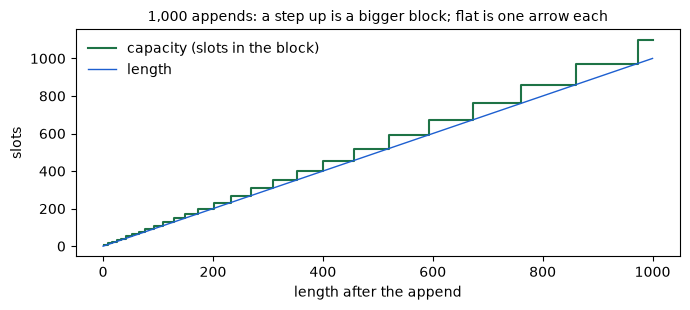

In [9]:
if plt is not None:
    xs = [n for n, _ in resizes] + [N]
    ys = [c for _, c in resizes] + [cap]
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.step(xs, ys, where="post", color="#1E7346", label="capacity (slots in the block)")
    ax.plot([0, N], [0, N], color="#1D5FD0", lw=1, label="length")
    ax.set_xlabel("length after the append")
    ax.set_ylabel("slots")
    ax.set_title(f"{N:,} appends: a step up is a bigger block; flat is one arrow each", fontsize=10)
    ax.legend(loc="upper left", frameon=False)
    plt.tight_layout()
    plt.show()

## 7. `insert(0, x)` shifts every arrow; a deque doesn't

`ins1` in `Objects/listobject.c` moves every arrow one slot to the right, the last one first, then writes the
new arrow into slot 0. Ours: 5 arrows moved to add one item, no new block (capacity
8). Compare the slots before and after: what was in slot *i* is now in slot *i* + 1.

A `collections.deque` is a chain of fixed-size blocks with an index at each end (`Modules/_collectionsmodule.c`).
`appendleft` writes into the free slot left of the first item, or links a new block on the left. The cell reads
the deque's left block and index (checking first that the slot it reads holds `id(d[0])`) and shows the old
first item still in the very same slot afterwards.

In [10]:
if RAW:
    nums = []
    for x in (3, 1, 4, 1, 7):
        nums.append(x)
    before = slots(nums)
    nums.insert(0, 2)
    after = slots(nums)
    print("after insert(0, 2):", nums)
    for i in range(len(after)):
        b = f"{before[i]:#x}" if i < len(before) else "(spare)"
        print(f"  slot {i}: {b:<16} → {after[i]:#x}")
    print("arrows that moved one slot right:", sum(after[i + 1] == before[i] for i in range(len(before))))

    d = collections.deque([3, 1, 4, 1, 7])
    left = ctypes.c_void_p.from_address(id(d) + 3 * P).value          # dequeobject.leftblock
    index = ctypes.c_ssize_t.from_address(id(d) + 5 * P).value        # dequeobject.leftindex

    def slot(block, i):                                               # block: leftlink, data[...], rightlink
        return ctypes.c_void_p.from_address(block + P + i * P).value

    if slot(left, index) == id(d[0]):
        first = d[0]
        d.appendleft(2)
        print(f"\ndeque: before appendleft the 3 is in slot {index} of block {left:#x}; "
              f"after, still there: {slot(left, index) == id(first)}")
    else:
        print("\ndeque peek skipped: this CPython lays the deque out differently")
else:
    print("skipped: needs CPython's list layout")

after insert(0, 2): [2, 3, 1, 4, 1, 7]
  slot 0: 0x103521f50      → 0x103521f30
  slot 1: 0x103521f10      → 0x103521f50
  slot 2: 0x103521f70      → 0x103521f10
  slot 3: 0x103521f10      → 0x103521f70
  slot 4: 0x103521fd0      → 0x103521f10
  slot 5: (spare)          → 0x103521fd0
arrows that moved one slot right: 5

deque: before appendleft the 3 is in slot 1 of block 0x10c04d550; after, still there: True


## Your turn

Two experiments, each changing one thing:

1. **Shrink it.** Append a hundred items to an empty list, then `pop()` them one by one and print `len` and
   `capacity` after each pop. When does the capacity drop, and to what? Find the line in `list_resize` that
   decides it.
2. **Fill it with something big.** Redo section 2 with a list of four lists of a hundred thousand ints each.
   Is `sys.getsizeof` of the outer list any different? Then add up `sys.getsizeof` of everything reachable from it
   (every inner list and every distinct int) and compare.

In [11]:
# 1. Shrink it
lst = []
for i in range(100):
    lst.append(i)
last = capacity(lst)
print("start: len", len(lst), "capacity", last)
while lst:
    lst.pop()
    if capacity(lst) != last:
        print(f"  len {len(lst):>3}: capacity {last} → {capacity(lst)}")
        last = capacity(lst)

start: len 100 capacity 108
  len  53: capacity 108 → 64
  len  31: capacity 64 → 40
  len  19: capacity 40 → 24
  len  11: capacity 24 → 16
  len   7: capacity 16 → 12
  len   5: capacity 12 → 8
  len   1: capacity 8 → 4
  len   0: capacity 4 → 0


In [12]:
# 2. Fill it with something big (about 40 MB while it runs)
big = [list(range(100_000)) for _ in range(4)]
print("sys.getsizeof(big):", sys.getsizeof(big))
seen, total = set(), 0
for obj in [big, *big, *(x for row in big for x in row)]:
    if id(obj) not in seen:
        seen.add(id(obj))
        total += sys.getsizeof(obj)
print(f"everything reachable from it: {total:,} bytes")
del big

sys.getsizeof(big): 88


everything reachable from it: 14,378,724 bytes
